# Know the customer

Challenge requirement 1: take any `account_id` and show their income, bills and fixed costs, savings buffer, and months of runway.

**To use it:** run all cells once, then change `ACCOUNT_ID` in the "Look up a customer" section and re-run that cell.

## Definitions

These are the judges' definitions from the [README](README.md#how-judges-calculate-the-numbers), all from `monthly_summary.csv`.

| Number | Definition |
| :-- | :-- |
| Typical money in (I) | Median of `money_in` |
| Typical spending (S) | Median of `money_out` |
| Household bills (H) | Median of `household_bills` |
| Typical fixed costs (F) | Median of `household_bills + insurance + loan_payments` |
| Loan payment (P) | `monthly_payment` if the loan is running at the end of 2025 (status C or D), otherwise 0 |
| Buffer (B) | Mean of `avg_daily_balance` over the account's last 6 rows |
| Runway | With no shock: B ÷ (S − I), capped at 120 months. 0 if B is zero or negative. "No shortfall" if S ≤ I |

## Additions to the judges' numbers

Each is shown next to the judges' numbers, and none replaces them. [`docs/discovery.md`](docs/discovery.md) explains why they're here.

| Number | Definition | Why |
| :-- | :-- | :-- |
| Bills on standing orders | Total of the account's `household bills` standing orders | Some bill transfers carry no label, so H misses them while they still count in S. The orders are an undated snapshot |
| Current fixed costs | Median of `household_bills + insurance`, plus any bills on standing orders above H, plus P | F is a lifetime median, so it misses recent loans and unlabelled bills, and still counts finished loans |
| Buffer in months of spending | B ÷ S | Runway mostly tracks how much money flows through an account, so this shows the savings on their own |
| Lowest balance | Lowest `min_balance` in the last 6 rows | An average hides the low point, and the low point is what predicted default |
| Last 6 months | The same medians over the last 6 rows | Shows when a lifetime median has gone stale. Six months can include seasonal peaks |

## Setup

In [1]:
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

DATA = "data/"
ms = pd.read_csv(DATA + "monthly_summary.csv").sort_values(["account_id", "month"], ignore_index=True)
ms["days_below_zero"] = ms["days_below_zero"].astype(int)  # some rows write this as 4.0
loans = pd.read_csv(DATA + "loans.csv").set_index("account_id")
accounts = pd.read_csv(DATA + "accounts.csv").set_index("account_id")
clients = pd.read_csv(DATA + "clients.csv", parse_dates=["birth_date"]).set_index("client_id")
dispositions = pd.read_csv(DATA + "dispositions.csv")
districts = pd.read_csv(DATA + "districts.csv").set_index("district_id")
standing_orders = pd.read_csv(DATA + "standing_orders.csv")
cards = pd.read_csv(DATA + "cards.csv")

rows_by_account = {a: x.reset_index(drop=True) for a, x in ms.groupby("account_id")}
orders_by_account = {a: x for a, x in standing_orders.groupby("account_id")}
people_by_account = {a: x for a, x in dispositions.groupby("account_id")}
card_by_disposition = cards.set_index("disposition_id").card_type.to_dict()
END_OF_DATA = pd.Timestamp("2025-12-31")

INCOME_LABELS = {"cash_deposits": "Cash deposits", "transfers_in": "Transfers in", "pension_in": "Pension", "interest_in": "Interest"}
SPEND_LABELS = {"cash_withdrawals_genuine": "Cash withdrawals", "household_bills": "Household bills", "insurance": "Insurance",
                "loan_payments": "Loan payments", "transfers_out_other": "Other transfers out",
                "card_withdrawals": "Card withdrawals", "bank_fees": "Bank fees"}

# Colours passed the dataviz palette validator as a set.
SURFACE, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
BLUE, ORANGE, AQUA, VIOLET = "#2a78d6", "#eb6834", "#1baf7a", "#6250d6"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE, "figure.dpi": 130,
    "font.family": "sans-serif", "font.sans-serif": ["Helvetica Neue", "Helvetica", "Arial", "DejaVu Sans"],
    "font.size": 9.5, "text.color": INK2, "axes.labelcolor": INK2, "axes.edgecolor": AXIS, "axes.linewidth": 0.8,
    "axes.titlesize": 11, "axes.titlecolor": INK, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlepad": 26,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "grid.color": GRID, "grid.linewidth": 0.7, "axes.spines.top": False, "axes.spines.right": False,
    "legend.frameon": False, "lines.linewidth": 2,
})
print(f"Loaded {len(rows_by_account):,} accounts and {len(ms):,} account-months.")

Loaded 4,500 accounts and 185,326 account-months.


## The calculation

`build_profile` works out one account's numbers and has no display code, so the shock and plan work can reuse it. `flags` turns those numbers into warnings.

In [2]:
def runway_months(buffer, gap):
    """README runway. None means no shortfall (120+)."""
    if buffer <= 0:
        return 0.0
    if gap <= 0:
        return None
    return round(min(buffer / gap, 120), 1)


def income_type(x):
    if x.pension_in.sum() > 0:
        return "Pension"
    if x.transfers_in.sum() > 0:
        return "Transfers"
    return "Cash only"


def parse_account_id(value):
    try:
        account_id = int(str(value).strip())
    except ValueError:
        raise ValueError(f"'{value}' isn't an account ID. IDs are whole numbers, like 20111.") from None
    if account_id not in rows_by_account:
        raise ValueError(f"Account {account_id} isn't in the data. IDs are whole numbers, like 20111.")
    return account_id


def build_profile(value):
    account_id = parse_account_id(value)
    x = rows_by_account[account_id]
    last6 = x.tail(6)
    fixed = x.household_bills + x.insurance + x.loan_payments
    bills_ins = x.household_bills + x.insurance
    loan = loans.loc[account_id] if account_id in loans.index else None

    I, S, H = x.money_in.median(), x.money_out.median(), x.household_bills.median()
    F, B = fixed.median(), last6.avg_daily_balance.mean()
    running = loan is not None and loan.status in ("C", "D")
    P = float(loan.monthly_payment) if running else 0.0

    people = people_by_account[account_id]
    owner = people[people.type == "owner"].iloc[0]
    client = clients.loc[owner.client_id]
    orders = orders_by_account.get(account_id)
    bill_orders = 0.0 if orders is None else float(orders.loc[orders.purpose == "household bills", "amount"].sum())
    leasing = 0.0 if orders is None else float(orders.loc[orders.purpose == "leasing", "amount"].sum())

    return dict(
        account_id=account_id, x=x, loan=loan, running=running, orders=orders,
        I=I, S=S, H=H, F=F, P=P, B=B,
        insurance=x.insurance.median(), loan_median=x.loan_payments.median(),
        bill_orders=bill_orders, leasing=leasing, bills_hidden=bill_orders > H * 1.1 + 1,
        current_fixed=bills_ins.median() + max(bill_orders - H, 0) + P,
        I6=last6.money_in.median(), S6=last6.money_out.median(), H6=last6.household_bills.median(),
        F6=(last6.household_bills + last6.insurance + last6.loan_payments).median(),
        lowest=last6.min_balance.min(), latest_balance=x.month_end_balance.iloc[-1],
        negative_months_12=int((x.tail(12).days_below_zero > 0).sum()),
        buffer_months=B / S if S > 0 and B > 0 else None,
        gap=S - I, runway=runway_months(B, S - I),
        income_type=income_type(x), first_month=x.month.iloc[0], last_month=x.month.iloc[-1], n_months=len(x),
        income_low=x.money_in.quantile(.1), income_high=x.money_in.quantile(.9),
        age=(END_OF_DATA - client.birth_date).days / 365.25,
        home=districts.loc[client.district_id], branch=districts.loc[accounts.loc[account_id, "district_id"]],
        opened=accounts.loc[account_id, "account_opened"], n_authorized=int((people.type != "owner").sum()),
        card=[card_by_disposition[d] for d in people.disposition_id if d in card_by_disposition],
    )


def flags(p):
    """Things a reader should know before trusting the numbers."""
    out = []
    if p["I"] == 0 and p["S"] == 0:
        out.append("**Little activity:** typical money in and spending are both $0, so most months have no movement and medians say little about this account.")
    elif p["I"] == 0:
        out.append("**Irregular income:** typical money in is $0, so most months have no income.")
    elif p["S"] == 0:
        out.append("**Irregular spending:** typical spending is $0, so most months have no spending. Runway will look safer than it may be.")
    if p["last_month"] != "2025-12":
        out.append(f"**Out of date:** this account's data stops at {p['last_month']}, so every number is as of then.")
    if p["B"] <= 0:
        out.append("**No buffer:** the buffer is zero or negative, so runway is 0.")
    if p["income_type"] == "Pension":
        out.append("**Pension income:** a layoff wouldn't stop this income, so a job-loss shock doesn't really fit.")
    elif p["income_type"] == "Cash only":
        out.append("**Cash income:** almost all money in is cash deposits, so the data can't show how much of it is pay.")
    if p["I"] > 2 * p["home"].average_salary:
        out.append(f"**High flow:** typical money in is over twice the home district's average salary ({money(p['home'].average_salary)}), so some of it may not be pay.")
    if p["bills_hidden"]:
        out.append(f"**Bills missing from H:** household bills standing orders total {money(p['bill_orders'])}, but H is only {money(p['H'])}. This is usually because the transfers carry no bills label, though they still count in S. A bills shock based on H will be too small.")
    elif p["H"] == 0:
        out.append("**No regular bills visible:** typical household bills are $0, so a bills shock won't change this account's numbers.")
    if p["running"] and p["loan_median"] == 0:
        out.append(f"**Recent loan missed by F:** typical fixed costs show $0 of loan payment, but {money(p['P'])} a month is due. Use current fixed costs.")
    if p["loan"] is not None and not p["running"] and p["loan_median"] > 0:
        out.append(f"**Finished loan still counted:** F includes {money(p['loan_median'])} of loan payments that have ended. Use current fixed costs.")
    if p["loan"] is not None and p["loan"].status in ("B", "D"):
        out.append(f"**Loan in trouble:** status is \"{p['loan'].status_meaning}\".")
    if p["running"] and p["x"].loan_payments.iloc[-1] == 0:
        out.append("**Missed payment:** the loan is running, but no payment was made in the last month of data.")
    if p["lowest"] < 0:
        out.append(f"**Went negative:** the balance fell to {money(p['lowest'])} in the last 6 months.")
    elif p["running"] and p["lowest"] < p["P"]:
        out.append(f"**Thin low point:** the lowest balance in the last 6 months ({money(p['lowest'])}) is under one loan payment. Before a loan, this was a strong warning sign of default.")
    if p["leasing"] > 0:
        out.append(f"**Leasing not counted:** there's a {money(p['leasing'])} leasing standing order, but no matching transfers in the data, so it isn't in S or F.")
    return out


def money(v):
    return f"-${abs(v):,.0f}" if v < 0 else f"${v:,.0f}"

def runway_text(p):
    return "No shortfall (120+)" if p["runway"] is None else f"{p['runway']:.1f} months"

In [3]:
# Every account, calculated in bulk. Gives "compared with other accounts" and a second code path to check against.
g = ms.groupby("account_id")
population = pd.DataFrame({
    "I": g.money_in.median(), "S": g.money_out.median(), "H": g.household_bills.median(),
    "F": (ms.household_bills + ms.insurance + ms.loan_payments).groupby(ms.account_id).median(),
    "B": ms.groupby("account_id").tail(6).groupby("account_id").avg_daily_balance.mean(),
})
population["buffer_months"] = population.B / population.S.where(population.S > 0)

def rank_text(column, value):
    if value is None:
        return "n/a"
    share = (population[column] < value).mean()
    return "Among the lowest" if share < 0.005 else f"Above {share:.0%} of accounts"

## The display

`know_the_customer` shows one account: a summary, the four things the challenge asks for, the detail behind them, then two charts.

In [4]:
def table(headers, rows, align=None):
    align = align or [":--"] + ["--:"] * (len(headers) - 1)
    lines = ["| " + " | ".join(headers) + " |", "| " + " | ".join(align) + " |"]
    lines += ["| " + " | ".join(str(c) for c in r) + " |" for r in rows]
    return "\n".join(lines)


def summary_sentence(p):
    x = p["x"]
    totals = x[list(INCOME_LABELS)].sum()
    source = INCOME_LABELS[totals.idxmax()].lower()
    pct = totals.max() / totals.sum()
    text = f"In a typical month, this account brings in **{money(p['I'])}** and spends **{money(p['S'])}**. {pct:.0%} of all its money in is {source}. "
    text += f"Fixed costs are **{money(p['current_fixed'])}** a month at current rates. "
    if p["buffer_months"] is None:
        text += f"The buffer is **{money(p['B'])}**. "
    else:
        text += f"The buffer is **{money(p['B'])}**, or {p['buffer_months']:.1f} months of spending. "
    if p["B"] <= 0:
        text += "With no buffer, runway is **0 months**."
    elif p["I"] == 0 and p["S"] == 0:
        text += "Most months have no movement, so the formula shows **no shortfall**, but that says little about this account."
    elif p["runway"] is None:
        text += "Typical money in covers typical spending, so there's **no shortfall**."
    else:
        text += f"Spending runs {money(p['gap'])} a month above money in, which gives **{p['runway']:.1f} months** of runway."
    return text


def plot_account(p):
    x = p["x"].tail(24)
    labels = pd.to_datetime(x.month).dt.strftime("%b %y").tolist()
    pos = np.arange(len(x))
    ticks = pos[::max(1, len(x) // 6)]
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.3))

    a = axes[0]
    a.grid(axis="y"); a.set_axisbelow(True)
    a.plot(pos, x.money_in, color=BLUE, label="Money in")
    a.plot(pos, x.money_out, color=ORANGE, label="Money out")
    a.set_title(f"Money in and out, last {len(x)} months")

    b = axes[1]
    b.grid(axis="y"); b.set_axisbelow(True)
    b.axvspan(pos[-min(6, len(x))] - 0.5, pos[-1] + 0.5, color=GRID, alpha=0.45, linewidth=0, label="Buffer window (last 6 months)")
    b.plot(pos, x.avg_daily_balance, color=AQUA, label="Average balance")
    b.plot(pos, x.min_balance, color=VIOLET, label="Lowest balance")
    if x.min_balance.min() < 0:
        b.axhline(0, color=INK2, linewidth=0.8)
    b.set_title(f"Balance, last {len(x)} months")

    for ax in axes:
        ax.set_xticks(ticks, [labels[i] for i in ticks])
        ax.set_xlim(-0.5, len(x) - 0.5)
        ax.yaxis.set_major_formatter(lambda v, _: money(v))
        ax.spines["left"].set_visible(False)
        ax.tick_params(axis="y", length=0)
        ax.legend(ncols=3, loc="lower left", bbox_to_anchor=(-0.02, 0.98), fontsize=8.5, handlelength=1.3, columnspacing=1.0, handletextpad=0.5)
    plt.tight_layout()
    plt.show()


def customer_report(p):
    x = p["x"]
    out = [f"## Account {p['account_id']}", summary_sentence(p)]

    who = [
        f"{p['income_type']} income",
        f"owner aged {p['age']:.0f}",
        f"lives in {p['home'].district_name}",
        f"account opened {p['opened']}",
        f"{p['n_months']} months of data ({p['first_month']} to {p['last_month']})",
    ]
    if p["n_authorized"]:
        who.append("1 authorized user" if p["n_authorized"] == 1 else f"{p['n_authorized']} authorized users")
    if p["card"]:
        who.append(f"{p['card'][0]} card")
    out.append("**Customer:** " + ", ".join(who) + ".")

    notes = flags(p)
    if notes:
        out.append("### Worth knowing\n\n" + "\n".join(f"- {n}" for n in notes))

    out.append("### The numbers\n\n" + table(
        ["Measure", "Value", "Last 6 months", "Compared with other accounts"],
        [
            ["**Income:** typical money in (I)", money(p["I"]), money(p["I6"]), rank_text("I", p["I"])],
            ["Typical spending (S)", money(p["S"]), money(p["S6"]), rank_text("S", p["S"])],
            ["**Bills:** household bills (H)", money(p["H"]), money(p["H6"]), rank_text("H", p["H"])],
            ["Bills on standing orders *(our addition)*", money(p["bill_orders"]), "", ""],
            ["**Fixed costs:** typical (F)", money(p["F"]), money(p["F6"]), rank_text("F", p["F"])],
            ["Current fixed costs *(our addition)*", money(p["current_fixed"]), "", ""],
            ["Loan payment (P)", money(p["P"]), "", ""],
            ["**Savings buffer (B)**", money(p["B"]), "", rank_text("B", p["B"])],
            ["Buffer in months of spending *(our addition)*", "n/a" if p["buffer_months"] is None else f"{p['buffer_months']:.1f}", "", rank_text("buffer_months", p["buffer_months"])],
            ["Lowest balance, last 6 months *(our addition)*", money(p["lowest"]), "", ""],
            ["**Runway, no shock**", runway_text(p), "", ""],
        ]))

    in_tot = x[list(INCOME_LABELS)].sum()
    in_rows = [[INCOME_LABELS[c], money(x[c].median()), f"{in_tot[c] / in_tot.sum():.0%}"] for c in in_tot.sort_values(ascending=False).index if in_tot[c] > 0]
    out.append("### Income\n\n" + table(["Source", "Typical month", "Share of all money in"], in_rows)
               + f"\n\nIn 8 of 10 months, money in was between {money(p['income_low'])} and {money(p['income_high'])}.")

    out_tot = x[list(SPEND_LABELS)].sum()
    if out_tot.sum() > 0:
        out_rows = [[SPEND_LABELS[c], money(x[c].median()), f"{out_tot[c] / out_tot.sum():.0%}"] for c in out_tot.sort_values(ascending=False).index if out_tot[c] > 0]
        out.append("### Spending, bills and fixed costs\n\n" + table(["Type", "Typical month", "Share of all money out"], out_rows)
                   + "\n\nTypical months are medians, so they don't add up to typical spending.")

    if p["loan"] is not None:
        l = p["loan"]
        out.append("### Loan\n\n" + table(["Started", "Amount", "Months", "Monthly payment", "Status"],
            [[l.loan_start, money(l.amount), l.duration_months, money(l.monthly_payment), l.status_meaning]], [":--", "--:", "--:", "--:", ":--"]))

    if p["orders"] is not None:
        rows = []
        for _, o in p["orders"].sort_values("amount", ascending=False).iterrows():
            purpose = o.purpose if isinstance(o.purpose, str) else "other"
            if purpose == "loan payment" and not p["running"]:
                purpose += " (no running loan, so not counted)"
            rows.append([purpose, money(o.amount)])
        out.append("### Standing orders\n\nAn undated snapshot from the end of the data.\n\n" + table(["Purpose", "Amount"], rows))

    return "\n\n".join(out)


def know_the_customer(value):
    try:
        p = build_profile(value)
    except ValueError as error:
        display(Markdown(f"**Can't show this customer.** {error}"))
        return None
    display(Markdown(customer_report(p)))
    plot_account(p)
    return p

## Look up a customer

Change the ID and re-run this cell.

## Account 20111

In a typical month, this account brings in **$6,339** and spends **$8,600**. 99% of all its money in is cash deposits. Fixed costs are **$2,330** a month at current rates. The buffer is **$17,612**, or 2.0 months of spending. Spending runs $2,260 a month above money in, which gives **7.8 months** of runway.

**Customer:** Cash only income, owner aged 60, lives in Rokycany, account opened 2022-11-29, 38 months of data (2022-11 to 2025-12).

### Worth knowing

- **Cash income:** almost all money in is cash deposits, so the data can't show how much of it is pay.
- **No regular bills visible:** typical household bills are $0, so a bills shock won't change this account's numbers.
- **Loan in trouble:** status is "running, client in debt".

### The numbers

| Measure | Value | Last 6 months | Compared with other accounts |
| :-- | --: | --: | --: |
| **Income:** typical money in (I) | $6,339 | $6,646 | Above 45% of accounts |
| Typical spending (S) | $8,600 | $7,448 | Above 55% of accounts |
| **Bills:** household bills (H) | $0 | $0 | Among the lowest |
| Bills on standing orders *(our addition)* | $0 |  |  |
| **Fixed costs:** typical (F) | $2,330 | $2,330 | Above 62% of accounts |
| Current fixed costs *(our addition)* | $2,330 |  |  |
| Loan payment (P) | $2,330 |  |  |
| **Savings buffer (B)** | $17,612 |  | Above 37% of accounts |
| Buffer in months of spending *(our addition)* | 2.0 |  | Above 26% of accounts |
| Lowest balance, last 6 months *(our addition)* | $10,418 |  |  |
| **Runway, no shock** | 7.8 months |  |  |

### Income

| Source | Typical month | Share of all money in |
| :-- | --: | --: |
| Cash deposits | $6,232 | 99% |
| Interest | $76 | 1% |

In 8 of 10 months, money in was between $129 and $27,772.

### Spending, bills and fixed costs

| Type | Typical month | Share of all money out |
| :-- | --: | --: |
| Cash withdrawals | $7,425 | 90% |
| Loan payments | $2,330 | 10% |
| Bank fees | $9 | 0% |

Typical months are medians, so they don't add up to typical spending.

### Loan

| Started | Amount | Months | Monthly payment | Status |
| :-- | --: | --: | --: | :-- |
| 2023-12-15 | $139,811 | 60 | $2,330 | running, client in debt |

### Standing orders

An undated snapshot from the end of the data.

| Purpose | Amount |
| :-- | --: |
| loan payment | $2,330 |

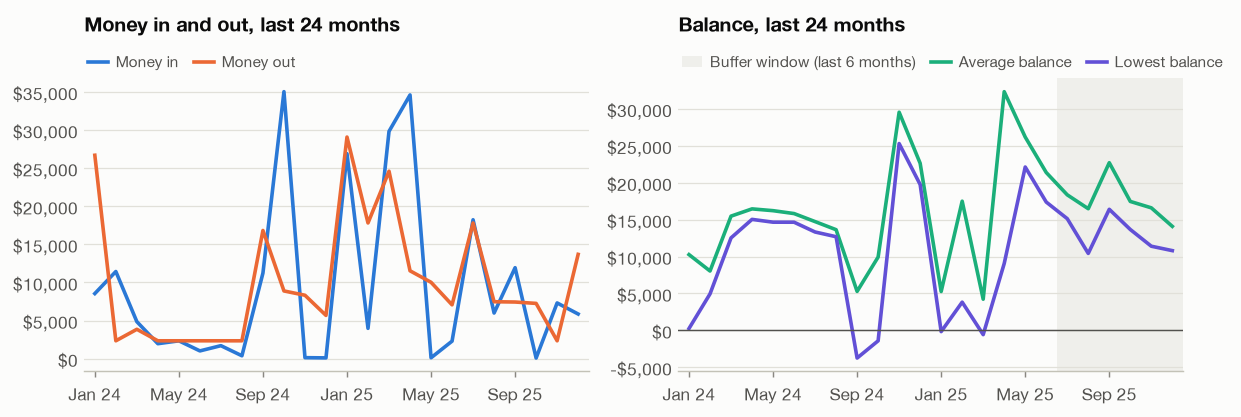

In [5]:
ACCOUNT_ID = 20111

profile = know_the_customer(ACCOUNT_ID)

## Harder accounts

A judge can pick any account, so these show how the display handles unusual ones.

### A pensioner with bills that H misses

## Account 20176

In a typical month, this account brings in **$4,281** and spends **$3,212**. 97% of all its money in is pension. Fixed costs are **$1,189** a month at current rates. The buffer is **$34,694**, or 10.8 months of spending. Typical money in covers typical spending, so there's **no shortfall**.

**Customer:** Pension income, owner aged 66, lives in Olomouc, account opened 2023-04-23, 33 months of data (2023-04 to 2025-12).

### Worth knowing

- **Pension income:** a layoff wouldn't stop this income, so a job-loss shock doesn't really fit.
- **Bills missing from H:** household bills standing orders total $1,189, but H is only $40. This is usually because the transfers carry no bills label, though they still count in S. A bills shock based on H will be too small.

### The numbers

| Measure | Value | Last 6 months | Compared with other accounts |
| :-- | --: | --: | --: |
| **Income:** typical money in (I) | $4,281 | $4,321 | Above 36% of accounts |
| Typical spending (S) | $3,212 | $3,715 | Above 32% of accounts |
| **Bills:** household bills (H) | $40 | $40 | Above 28% of accounts |
| Bills on standing orders *(our addition)* | $1,189 |  |  |
| **Fixed costs:** typical (F) | $40 | $40 | Above 25% of accounts |
| Current fixed costs *(our addition)* | $1,189 |  |  |
| Loan payment (P) | $0 |  |  |
| **Savings buffer (B)** | $34,694 |  | Above 77% of accounts |
| Buffer in months of spending *(our addition)* | 10.8 |  | Above 90% of accounts |
| Lowest balance, last 6 months *(our addition)* | $27,780 |  |  |
| **Runway, no shock** | No shortfall (120+) |  |  |

### Income

| Source | Typical month | Share of all money in |
| :-- | --: | --: |
| Pension | $4,174 | 97% |
| Interest | $107 | 2% |
| Cash deposits | $0 | 0% |

In 8 of 10 months, money in was between $4,179 and $4,318.

### Spending, bills and fixed costs

| Type | Typical month | Share of all money out |
| :-- | --: | --: |
| Cash withdrawals | $2,014 | 68% |
| Other transfers out | $1,148 | 31% |
| Household bills | $40 | 1% |
| Bank fees | $9 | 0% |

Typical months are medians, so they don't add up to typical spending.

### Standing orders

An undated snapshot from the end of the data.

| Purpose | Amount |
| :-- | --: |
| household bills | $1,148 |
| household bills | $40 |

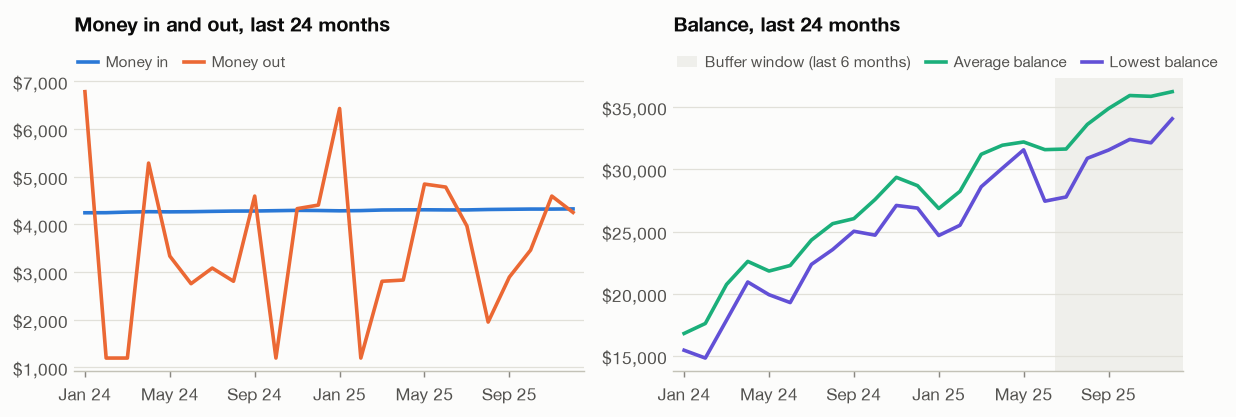

In [6]:
_ = know_the_customer(20176)

### A recent loan that F misses

## Account 20208

In a typical month, this account brings in **$20,395** and spends **$17,058**. 100% of all its money in is cash deposits. Fixed costs are **$7,749** a month at current rates. The buffer is **$29,778**, or 1.7 months of spending. Typical money in covers typical spending, so there's **no shortfall**.

**Customer:** Cash only income, owner aged 57, lives in Benesov, account opened 2023-11-29, 26 months of data (2023-11 to 2025-12), classic card.

### Worth knowing

- **Cash income:** almost all money in is cash deposits, so the data can't show how much of it is pay.
- **High flow:** typical money in is over twice the home district's average salary ($5,353), so some of it may not be pay.
- **Recent loan missed by F:** typical fixed costs show $0 of loan payment, but $1,355 a month is due. Use current fixed costs.

### The numbers

| Measure | Value | Last 6 months | Compared with other accounts |
| :-- | --: | --: | --: |
| **Income:** typical money in (I) | $20,395 | $26,983 | Above 90% of accounts |
| Typical spending (S) | $17,058 | $26,234 | Above 88% of accounts |
| **Bills:** household bills (H) | $6,393 | $6,393 | Above 97% of accounts |
| Bills on standing orders *(our addition)* | $6,393 |  |  |
| **Fixed costs:** typical (F) | $6,393 | $7,749 | Above 95% of accounts |
| Current fixed costs *(our addition)* | $7,749 |  |  |
| Loan payment (P) | $1,355 |  |  |
| **Savings buffer (B)** | $29,778 |  | Above 67% of accounts |
| Buffer in months of spending *(our addition)* | 1.7 |  | Above 18% of accounts |
| Lowest balance, last 6 months *(our addition)* | $8,906 |  |  |
| **Runway, no shock** | No shortfall (120+) |  |  |

### Income

| Source | Typical month | Share of all money in |
| :-- | --: | --: |
| Cash deposits | $20,271 | 100% |
| Interest | $78 | 0% |

In 8 of 10 months, money in was between $2,668 and $61,534.

### Spending, bills and fixed costs

| Type | Typical month | Share of all money out |
| :-- | --: | --: |
| Cash withdrawals | $14,159 | 77% |
| Household bills | $6,393 | 20% |
| Loan payments | $0 | 3% |
| Bank fees | $9 | 0% |

Typical months are medians, so they don't add up to typical spending.

### Loan

| Started | Amount | Months | Monthly payment | Status |
| :-- | --: | --: | --: | :-- |
| 2024-12-20 | $48,796 | 36 | $1,355 | running, OK so far |

### Standing orders

An undated snapshot from the end of the data.

| Purpose | Amount |
| :-- | --: |
| household bills | $6,393 |
| loan payment | $1,355 |

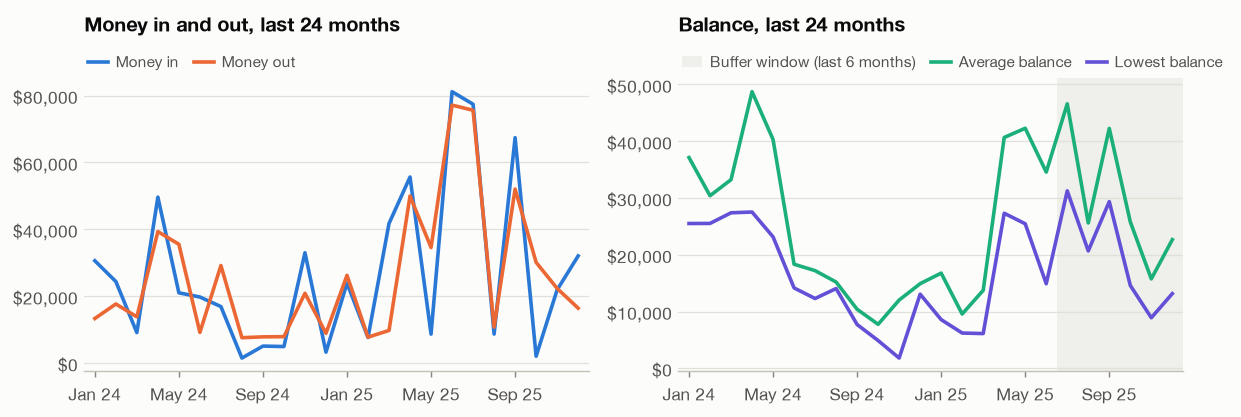

In [7]:
_ = know_the_customer(20208)

### A negative buffer

## Account 32078

In a typical month, this account brings in **$3,181** and spends **$2,967**. 99% of all its money in is cash deposits. Fixed costs are **$0** a month at current rates. The buffer is **-$2,513**. With no buffer, runway is **0 months**.

**Customer:** Cash only income, owner aged 44, lives in Praha - zapad, account opened 2020-03-08, 70 months of data (2020-03 to 2025-12).

### Worth knowing

- **No buffer:** the buffer is zero or negative, so runway is 0.
- **Cash income:** almost all money in is cash deposits, so the data can't show how much of it is pay.
- **No regular bills visible:** typical household bills are $0, so a bills shock won't change this account's numbers.
- **Went negative:** the balance fell to -$8,048 in the last 6 months.

### The numbers

| Measure | Value | Last 6 months | Compared with other accounts |
| :-- | --: | --: | --: |
| **Income:** typical money in (I) | $3,181 | $3,108 | Above 23% of accounts |
| Typical spending (S) | $2,967 | $3,811 | Above 30% of accounts |
| **Bills:** household bills (H) | $0 | $0 | Among the lowest |
| Bills on standing orders *(our addition)* | $0 |  |  |
| **Fixed costs:** typical (F) | $0 | $0 | Among the lowest |
| Current fixed costs *(our addition)* | $0 |  |  |
| Loan payment (P) | $0 |  |  |
| **Savings buffer (B)** | -$2,513 |  | Among the lowest |
| Buffer in months of spending *(our addition)* | n/a |  | n/a |
| Lowest balance, last 6 months *(our addition)* | -$8,048 |  |  |
| **Runway, no shock** | 0.0 months |  |  |

### Income

| Source | Typical month | Share of all money in |
| :-- | --: | --: |
| Cash deposits | $3,108 | 99% |
| Interest | $57 | 1% |

In 8 of 10 months, money in was between $3,111 and $4,764.

### Spending, bills and fixed costs

| Type | Typical month | Share of all money out |
| :-- | --: | --: |
| Cash withdrawals | $2,958 | 100% |
| Bank fees | $9 | 0% |

Typical months are medians, so they don't add up to typical spending.

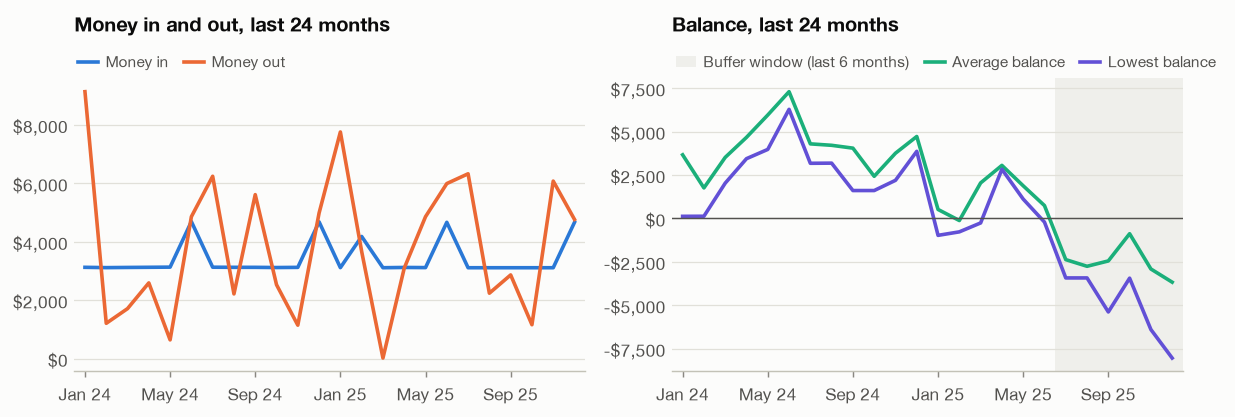

In [8]:
_ = know_the_customer(32078)

### Almost no activity, and data that stops early

## Account 21132

In a typical month, this account brings in **$0** and spends **$0**. 100% of all its money in is cash deposits. Fixed costs are **$0** a month at current rates. The buffer is **$8,312**. Most months have no movement, so the formula shows **no shortfall**, but that says little about this account.

**Customer:** Cash only income, owner aged 44, lives in Prerov, account opened 2023-01-27, 35 months of data (2023-01 to 2025-11).

### Worth knowing

- **Little activity:** typical money in and spending are both $0, so most months have no movement and medians say little about this account.
- **Out of date:** this account's data stops at 2025-11, so every number is as of then.
- **Cash income:** almost all money in is cash deposits, so the data can't show how much of it is pay.
- **No regular bills visible:** typical household bills are $0, so a bills shock won't change this account's numbers.

### The numbers

| Measure | Value | Last 6 months | Compared with other accounts |
| :-- | --: | --: | --: |
| **Income:** typical money in (I) | $0 | $1,573 | Among the lowest |
| Typical spending (S) | $0 | $0 | Among the lowest |
| **Bills:** household bills (H) | $0 | $0 | Among the lowest |
| Bills on standing orders *(our addition)* | $0 |  |  |
| **Fixed costs:** typical (F) | $0 | $0 | Among the lowest |
| Current fixed costs *(our addition)* | $0 |  |  |
| Loan payment (P) | $0 |  |  |
| **Savings buffer (B)** | $8,312 |  | Above 3% of accounts |
| Buffer in months of spending *(our addition)* | n/a |  | n/a |
| Lowest balance, last 6 months *(our addition)* | $5,726 |  |  |
| **Runway, no shock** | No shortfall (120+) |  |  |

### Income

| Source | Typical month | Share of all money in |
| :-- | --: | --: |
| Cash deposits | $0 | 100% |

In 8 of 10 months, money in was between $0 and $2,605.

### Spending, bills and fixed costs

| Type | Typical month | Share of all money out |
| :-- | --: | --: |
| Cash withdrawals | $0 | 100% |

Typical months are medians, so they don't add up to typical spending.

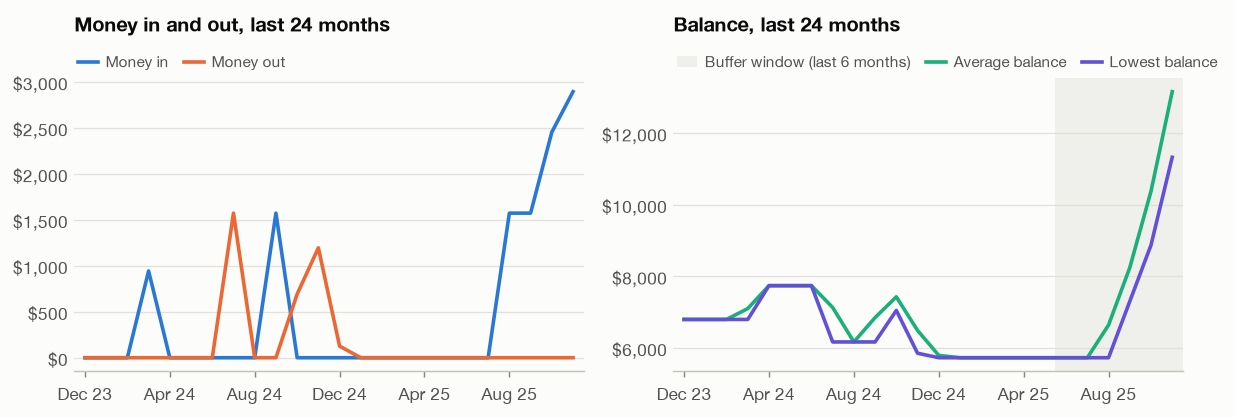

In [9]:
_ = know_the_customer(21132)

### An ID that doesn't exist

In [10]:
_ = know_the_customer(12345)
_ = know_the_customer("abc")

**Can't show this customer.** Account 12345 isn't in the data. IDs are whole numbers, like 20111.

**Can't show this customer.** 'abc' isn't an account ID. IDs are whole numbers, like 20111.

## Checks

These confirm the display can be trusted live: it works on every account, it matches a separate calculation, and its warnings match the counts in [`docs/discovery.md`](docs/discovery.md).

In [11]:
all_profiles = {a: build_profile(a) for a in rows_by_account}
all_flags = {a: flags(p) for a, p in all_profiles.items()}
check = pd.DataFrame({a: {k: p[k] for k in ["I", "S", "H", "F", "B"]} for a, p in all_profiles.items()}).T.sort_index()

# 1. Every account matches the bulk calculation.
diff = (check.astype(float) - population[["I", "S", "H", "F", "B"]].sort_index()).abs().max()
assert diff.max() < 1e-9, diff
assert len(check) == 4_500

# 2. Runway follows the README on every account.
for a, p in all_profiles.items():
    if p["B"] <= 0:
        assert p["runway"] == 0
    elif p["S"] <= p["I"]:
        assert p["runway"] is None
    else:
        assert 0 <= p["runway"] <= 120

# 3. Loan payment follows the README.
assert sum(p["P"] > 0 for p in all_profiles.values()) == 448

# 4. Warning counts match docs/discovery.md.
count = lambda text: sum(any(text in f for f in fl) for fl in all_flags.values())
expected = {"Out of date": 76, "No buffer": 23, "Pension income": 740, "Cash income": 2894,
            "Recent loan missed by F": 197, "Finished loan still counted": 79, "Missed payment": 12, "Little activity": 10,
            "Bills missing from H": 293, "Leasing not counted": 341}
found = {k: count(k) for k in expected}
assert found == expected, found
assert count("Little activity") + count("Irregular income") == 14 and count("Little activity") + count("Irregular spending") == 77
assert sum(p["H"] == 0 for p in all_profiles.values()) == 1225

# 5. Every account's report builds.
reports = {a: customer_report(p) for a, p in all_profiles.items()}
assert all(f"## Account {a}" in r and not re.search(r"\bnan\b", r, re.I) for a, r in reports.items())

flag_names = ["Little activity", "Irregular income", "Irregular spending", "Out of date", "No buffer", "Pension income", "Cash income", "High flow",
              "No regular bills visible", "Recent loan missed by F", "Finished loan still counted", "Loan in trouble",
              "Missed payment", "Went negative", "Thin low point", "Leasing not counted", "Bills missing from H"]
display(pd.Series({k: count(k) for k in flag_names}, name="accounts").to_frame())

runways = pd.Series([p["runway"] for p in all_profiles.values()], dtype=float)
print(f"No shortfall: {runways.isna().sum():,}. Runway of 0: {(runways == 0).sum()}. Runway under 6 months: {(runways < 6).sum()}. Accounts with no warnings: {sum(not f for f in all_flags.values())}.")
print("All checks passed.")

,accounts
Little activity,10
Irregular income,4
Irregular spending,67
Out of date,76
No buffer,23
Pension income,740
Cash income,2894
High flow,1402
No regular bills visible,1063
Recent loan missed by F,197


No shortfall: 3,315. Runway of 0: 24. Runway under 6 months: 120. Accounts with no warnings: 324.
All checks passed.
